1.1 第⼀个代码框：⾝份与环境记录

In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd

# =========这里改成你的学号========
STUDENT_ID = 20244080219

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] exp01_env
[学号] 20244080219
[机器指纹] 94c2312533b046bb
[RUN_ID] 20244080219-94c2312533b046bb


实验1：NumPy 数组、数据类型与索引

任务 1：int、float、bool ndarray，对比 Python 列表

In [2]:
# 创建三类数组
arr_int = np.array([1,2,3,4])
arr_float = np.array([1.1,2.2,3.3])
arr_bool = np.array([True, False, True])

print("====整数数组====")
print(f"dtype:{arr_int.dtype}, shape:{arr_int.shape}, ndim:{arr_int.ndim}")
print("====浮点数数组====")
print(f"dtype:{arr_float.dtype}, shape:{arr_float.shape}, ndim:{arr_float.ndim}")
print("====布尔数组====")
print(f"dtype:{arr_bool.dtype}, shape:{arr_bool.shape}, ndim:{arr_bool.ndim}")


====整数数组====
dtype:int64, shape:(4,), ndim:1
====浮点数数组====
dtype:float64, shape:(3,), ndim:1
====布尔数组====
dtype:bool, shape:(3,), ndim:1


解释：
numpy 数组：**同数组所有元素必须是同一个数据类型**，内存连续，运算速度快；
Python 列表：可以存放不同类型对象，内存分散，循环运算慢。

任务 2：arange 修改形状 reshape

In [3]:
a = np.arange(12)
print("原始一维数组：", a)

a1 = a.reshape(3,4)
print("\nreshape(3,4):\n", a1)

a2 = a.reshape(2,3,2)
print("\nreshape(2,3,2):\n", a2)


原始一维数组： [ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


解释：reshape 要求新 shape 所有维度相乘等于数组总元素个数**，这里 3*4=12；2*3*2=12。

任务 3：对 (3,4) 数组索引

In [4]:
arr = np.arange(12).reshape(3,4)
print("原数组:\n",arr)

# 取第2行（numpy从0开始，第二行索引是1）
row2 = arr[1,:]
print("\n第2行：",row2, "shape:", row2.shape)

# 取1~3列，列索引1,2,3
col1_3 = arr[:,1:4]
print("\n第1至3列：\n",col1_3, "shape:", col1_3.shape)

# 大于6的元素
gt6 = arr[arr>6]
print("\n大于6元素：",gt6, "shape:", gt6.shape)


原数组:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第2行： [4 5 6 7] shape: (4,)

第1至3列：
 [[ 1  2  3]
 [ 5  6  7]
 [ 9 10 11]] shape: (3, 3)

大于6元素： [ 7  8  9 10 11] shape: (5,)


任务 4：布尔条件筛选

In [5]:
x = np.arange(10)
# 小于2 或 大于7
cond1 = x[(x<2) | (x>7)]
# 大于3并且小于7
cond2 = x[(x>3) & (x<7)]

# 等价写法用logical_or / logical_and
cond1_2 = x[np.logical_or(x<2, x>7)]
cond2_2 = x[np.logical_and(x>3, x<7)]

print("小于2或大于7：", cond1)
print("大于3且小于7：", cond2)


小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]


解释：布尔条件必须每个条件加括号，`|`代表或，`&`代表与。

任务 5：逐元素乘法 * /multiply 和矩阵乘法 @ /matmul

In [6]:
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])

elem_mul1 = A * B
elem_mul2 = np.multiply(A,B)

mat_mul1 = A @ B
mat_mul2 = np.matmul(A,B)

print("逐元素乘法 *\n",elem_mul1)
print("np.multiply\n",elem_mul2)
print("矩阵乘法 @\n",mat_mul1)
print("np.matmul\n",mat_mul2)


逐元素乘法 *
 [[ 5 12]
 [21 32]]
np.multiply
 [[ 5 12]
 [21 32]]
矩阵乘法 @
 [[19 22]
 [43 50]]
np.matmul
 [[19 22]
 [43 50]]


解释：
- `*` / `np.multiply()`：**逐元素相乘，对应位置元素相乘**
- `@` / `np.matmul()`：标准**矩阵乘法（行列点积）**，遵循线性代数矩阵运算规则。

实验 2：随机抽样、统计、缺失值

In [7]:
np.random.seed(42) #固定随机种子！！

#任务1：生成1000个成绩，均值70标准差10，clip限制0‑100
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print(f"样本数:{len(scores)}")
print(f"最小值:{scores.min():.2f},最大值:{scores.max():.2f}")
print(f"均值:{scores.mean():.2f},标准差:{scores.std():.2f}")
print(f"极差:{scores.max()-scores.min():.2f}")

#任务2：从1‑11不放回抽5个；均匀抽样；加权抽样
arr_pool = np.arange(1,11)
sample_uniform = np.random.choice(arr_pool, size=5, replace=False)
#加权：权重等于数字大小
p_weight = arr_pool / arr_pool.sum()
sample_weighted = np.random.choice(arr_pool, size=5, replace=False, p=p_weight)
print("\n均匀不放回抽样：", sample_uniform)
print("按数值大小加权抽样：", sample_weighted)

#任务3：随机排列不改变原数组 vs 原地打乱
origin = np.array([1,2,3,4,5])
copy_shuffle = np.random.permutation(origin) #返回新数组，原数组不变
print("\npermutation:原数组",origin,"返回结果",copy_shuffle)

origin2 = np.array([1,2,3,4,5])
np.random.shuffle(origin2) #原地修改原数组
print("shuffle原地打乱后原数组：", origin2)

#任务4：设置nan缺失值
scores_nan = scores.copy()
scores_nan[[9,19,29]] = np.nan #第10、20、30个，索引从0开始
nan_count = np.sum(np.isnan(scores_nan))
mean_normal = np.mean(scores_nan) #普通均值，遇到nan结果nan
mean_ignore_nan = np.nanmean(scores_nan) #忽略nan求均值

print(f"\n缺失值数量:{nan_count}")
print(f"普通np.mean(含nan): {mean_normal}")
print(f"np.nanmean忽略缺失值:{mean_ignore_nan:.2f}")


样本数:1000
最小值:37.59,最大值:100.00
均值:70.18,标准差:9.76
极差:62.41

均匀不放回抽样： [ 4  9  2  6 10]
按数值大小加权抽样： [10  2  8  9  6]

permutation:原数组 [1 2 3 4 5] 返回结果 [5 1 3 2 4]
shuffle原地打乱后原数组： [1 5 2 4 3]

缺失值数量:3
普通np.mean(含nan): nan
np.nanmean忽略缺失值:70.20


解释：普通`np.mean()`数组包含`np.nan`，输出直接为 nan；必须使用`np.nanmean/nanstd`系列函数跳过缺失值。

In [8]:
#任务5：保存成绩+序号，给实验4使用，内存表格，不写磁盘
idx_arr = np.arange(len(scores_nan))
exp2_table = pd.DataFrame({"index":idx_arr,"score":scores_nan})


实验 3 SciPy 数值计算 + Matplotlib 可视化

In [9]:
from scipy import linalg
from scipy.optimize import root, minimize
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
np.random.seed(42)


任务 1：解线性方程组 \(3x+y=9;\ x+2y=8\)

In [10]:
A_mat = np.array([[3,1],[1,2]])
b_vec = np.array([9,8])
sol = linalg.solve(A_mat,b_vec)
print(f"方程组解 x={sol[0]}, y={sol[1]}")
#代入验证
print("代入3x+y：", 3*sol[0]+sol[1])
print("代入x+2y：", sol[0]+2*sol[1])


方程组解 x=2.000000000000001, y=2.9999999999999996
代入3x+y： 9.000000000000002
代入x+2y： 8.0


任务 2：求 \(x^2-2=0\) 的正负根

In [11]:
def f(x):
    return x**2 -2

#正根，初猜x=2
res_pos = root(f, x0=2)
#负根，初猜x=-2
res_neg = root(f, x0=-2)

print("正根求解成功?",res_pos.success,"结果",res_pos.x,"函数值",f(res_pos.x))
print("负根求解成功?",res_neg.success,"结果",res_neg.x,"函数值",f(res_neg.x))


正根求解成功? True 结果 [1.41421356] 函数值 [8.8817842e-16]
负根求解成功? True 结果 [-1.41421356] 函数值 [8.8817842e-16]


任务 3：最小化 \(f(x)=x^2+x+2\)

In [12]:
def func_min(x):
    return x**2 + x + 2

res_min = minimize(func_min, x0=0)
print("极小点x：",res_min.x)
print("极小函数值：",res_min.fun)
#解析解 x=-0.5，最小值=1.75，对比输出


极小点x： [-0.50000001]
极小函数值： 1.75


任务 4：独立样本 t 检验

In [13]:
s1 = np.random.normal(loc=0,scale=1,size=100)
s2 = np.random.normal(loc=1,scale=1,size=100)
t_stat, p_val = ttest_ind(s1,s2)
print(f"t统计量={t_stat:.3f}, p值={p_val:.4f}")
alpha =0.05
if p_val < alpha:
    print("p<0.05，拒绝原假设，两组均值存在显著差异")
else:
    print("p>=0.05，不能拒绝原假设")


t统计量=-8.551, p值=0.0000
p<0.05，拒绝原假设，两组均值存在显著差异


任务 5 Matplotlib 绘图

d:\Miniconda3\envs\exp01_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp01_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp01_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp01_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32489 (\N{CJK UNIFIED IDEOGRAPH-7EE9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp01_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGRAPH-76F4}) missing fro

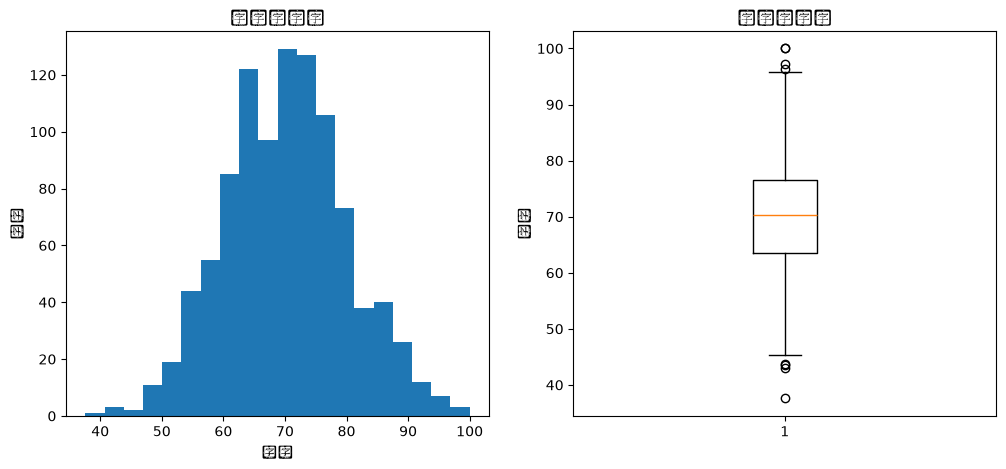

d:\Miniconda3\envs\exp01_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp01_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


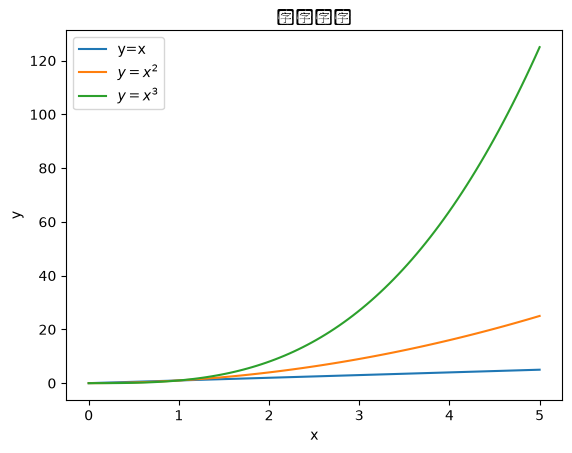

In [14]:
#①实验2成绩直方图+箱线图
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.hist(scores, bins=20)
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")

plt.subplot(1,2,2)
plt.boxplot(scores)
plt.title("成绩箱线图")
plt.ylabel("分数")
plt.show()

#② y=x, y=x², y=x³，0≤x≤5
x = np.linspace(0,5,100)
y1 = x
y2 = x**2
y3 = x**3

plt.figure()
plt.plot(x,y1,label="y=x")
plt.plot(x,y2,label="$y=x^2$")
plt.plot(x,y3,label="$y=x^3$")
plt.title("函数曲线")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


实验 4 pandas Series、DataFrame

In [15]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name") #行索引设置为姓名

#任务1：增加Total总分，Average平均分
df["Total"] = df["Math"]+df["English"]+df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：",df.index.tolist())
print("列名：",df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n统计信息：")
print(df.describe())

#任务2 loc iloc读取Carol；筛选平均分>=80
print("\n====Carol记录 loc按名字====")
print(df.loc["Carol"])
#iloc按行号，Carol是第2行，索引1
print("\n====Carol记录 iloc====")
print(df.iloc[1])

high_avg = df[df["Average"]>=80]
print("\n平均分>=80学生：")
print(high_avg)

#任务3 axis=0列均值；axis=1行均值
col_mean = df[["Math","English","Python"]].mean(axis=0)
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("\n各科列均值(axis=0):")
print(col_mean)
print("\n每个人行均值(axis=1):")
print(row_mean)

#任务4 apply求最高分；agg；rank排名
df["max_score"] = df[["Math","English","Python"]].apply(lambda row: row.max(), axis=1)
print("\n每个人三科最高分：")
print(df["max_score"])

stat_agg = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\nagg每科min mean max")
print(stat_agg)

#Python成绩排名
df["py_rank"] = df["Python"].rank(ascending=False)
print("\nPython成绩排名")
print(df[["Python","py_rank"]])

#任务5 groupby分组，transform
group_stat = df.groupby("Group")[["Math","English","Python"]].agg(["count","mean"])
print("\n分组统计人数和三科平均")
print(group_stat)

#transform增加本组Python平均分
df["group_python_mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加组内Python平均分列")
print(df)

#任务6 filter保留组Python平均分>=80
group_filter = df.groupby("Group").filter(lambda g: g["Python"].mean() >=80)
print("\nPython组平均>=80的学生")
print(group_filter)

#任务7 协方差、相关系数矩阵
sub_df = df[["Math","English","Python"]]
cov_mat = sub_df.cov()
corr_mat = sub_df.corr()
print("\n协方差矩阵")
print(cov_mat)
print("\n皮尔逊相关系数矩阵")
print(corr_mat)


行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

====Carol记录 loc按名字====
Group              B


解释：挑选两科，解释协方差正负；相关系数绝对值越接近 1 线性相关性越强。